# 02 — Model Training & Evaluation

**Task:** predict district-level paddy yield (kg/ha) for each season.

**Main model:** **Explainable Boosting Machine (EBM)**, which was not covered in the lectures. It is compared with:
- a naive baseline (the district's recent average)
- Ridge regression, the linear model from the lectures
- tuned **Random Forest** and **XGBoost**, the strongest ensemble models from the lectures

**Evaluation:**
- The data is split **by time**, so the model is always tested on future seasons it has never seen.
- Hyperparameters are tuned on a separate validation period.
- The test set is used **once**, at the end.

In [1]:
from pathlib import Path
import time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid, ParameterSampler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from interpret.glassbox import ExplainableBoostingRegressor

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, MODELS = ROOT / "reports" / "figures", ROOT / "models"
FIG.mkdir(parents=True, exist_ok=True); MODELS.mkdir(exist_ok=True)

COLORS = {"Naive baseline": "#b5b4ae", "Ridge": "#e87ba4", "Random Forest": "#1baf7a",
          "XGBoost": "#eda100", "EBM": "#2a78d6"}
SEASON_COLORS = {"Maha": "#2a78d6", "Yala": "#eb6834"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "font.size": 10, "lines.linewidth": 2, "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()

df = pd.read_csv(ROOT / "data_processed" / "paddy_dataset.csv")
df.shape

(2244, 32)

## 1. Features

The features come from the EDA in notebook 01. Columns that are only known **after harvest** are excluded to avoid leakage:
- harvested area
- harvest ratio
- the separate yields for each irrigation type

`sown_total` is log-transformed because district paddy areas range from tens of hectares to more than 100,000 ha.

### Lag features (past yields)

A first version of this notebook used **only weather and irrigation features**. Every model then lost to the naive baseline on
2021–2025. The models kept predicting the pre-2021 yield level of about 4,600 kg/ha, but after the fertilizer ban Maha yields stayed
about 700 kg/ha lower for three years. That run's scores are saved in `reports/test_scores_no_lag.csv`.

We therefore add three **lag features**. All of them are known **before** the season starts, so they do not leak information:

| Feature | Meaning |
|---|---|
| `lag_prev_season` | yield of the season just before this one. For Maha, that is last Yala. For Yala, it is the Maha harvested a few weeks earlier. |
| `lag_same_season` | yield of the same season one year earlier |
| `roll3_same_season` | mean yield of the same season over the previous 3 years (at least 2 must exist) |

The seasons are ordered in time as … → Maha *Y* → Yala *Y* → Maha *Y+1* → … If a district has a gap (for example in the war years),
the lag is left missing instead of being taken from a season further back.

In [2]:
df["t"] = df["year"] * 2 + (df["season"] == "Yala").astype(int)   # chronological season index
y_at = df.set_index(["district", "t"])["yield_total"]
lookup = lambda d, t: y_at.get((d, t), np.nan)

df["lag_prev_season"] = [lookup(d, t - 1) for d, t in zip(df.district, df.t)]
df["lag_same_season"] = [lookup(d, t - 2) for d, t in zip(df.district, df.t)]
past3 = np.array([[lookup(d, t - k) for k in (2, 4, 6)] for d, t in zip(df.district, df.t)])
df["roll3_same_season"] = np.where(np.sum(~np.isnan(past3), axis=1) >= 2, np.nanmean(past3, axis=1), np.nan)

(df.query("district == 'POLONNARUWA' and year >= 2021").sort_values("t")
   [["district", "season_label", "yield_total", "lag_prev_season", "lag_same_season", "roll3_same_season"]])

,district,season_label,yield_total,lag_prev_season,lag_same_season,roll3_same_season
2024,POLONNARUWA,2020/21 Maha,5220.000000,5244.0,5404.0,5109.000000
2047,POLONNARUWA,2021 Yala,5441.000000,5220.0,5244.0,5275.000000
2072,POLONNARUWA,2021/22 Maha,3103.000000,5441.0,5220.0,5233.000000
2095,POLONNARUWA,2022 Yala,4288.000000,3103.0,5441.0,5398.666667
2120,POLONNARUWA,2022/23 Maha,4416.000000,4288.0,3103.0,4575.666667
2143,POLONNARUWA,2023 Yala,4918.000000,4416.0,4288.0,4991.000000
2168,POLONNARUWA,2023/24 Maha,4697.000000,4918.0,4416.0,4246.333333
2191,POLONNARUWA,2024 Yala,5716.000000,4697.0,4918.0,4882.333333
2216,POLONNARUWA,2024/25 Maha,4794.000000,5716.0,4697.0,4072.000000
2239,POLONNARUWA,2025 Yala,5191.383282,4794.0,5716.0,4974.000000


In [3]:
CATEGORICAL = ["district", "season"]
NUMERIC = ["year", "log_sown_total", "sown_share_major", "sown_share_minor", "sown_share_rainfed",
           "rain_total_mm", "rain_min_month_mm", "rain_max_month_mm", "rain_cv", "rain_pre_season_mm",
           "temp_mean_c", "temp_max_c", "temp_min_c", "humidity_pct", "solar_mj_m2_day", "wind_m_s",
           "lag_prev_season", "lag_same_season", "roll3_same_season"]
FEATURES = CATEGORICAL + NUMERIC
TARGET = "yield_total"

df["log_sown_total"] = np.log1p(df["sown_total"])
print(len(FEATURES), "features:", FEATURES)
print("Missing lags (%):", (df[["lag_prev_season", "lag_same_season", "roll3_same_season"]].isna().mean() * 100).round(1).to_dict())

21 features: ['district', 'season', 'year', 'log_sown_total', 'sown_share_major', 'sown_share_minor', 'sown_share_rainfed', 'rain_total_mm', 'rain_min_month_mm', 'rain_max_month_mm', 'rain_cv', 'rain_pre_season_mm', 'temp_mean_c', 'temp_max_c', 'temp_min_c', 'humidity_pct', 'solar_mj_m2_day', 'wind_m_s', 'lag_prev_season', 'lag_same_season', 'roll3_same_season']
Missing lags (%): {'lag_prev_season': 5.6, 'lag_same_season': 3.8, 'roll3_same_season': 5.4}


## 2. Time-based train / validation / test split

| Set | Harvest years | Purpose |
|---|---|---|
| Train | 1981–2017 | fit the models |
| Validation | 2018–2020 | choose hyperparameters |
| Test | 2021–2025 | final, one-time evaluation |

A random split would put the same district and year in both train and test. That would **leak** the time trend and inflate the scores.

**Why `fertilizer_shock` is not a feature:** the flag is 1 only in 2022, which falls in the **test** period. The model never sees a
fertilizer shock during training, so it cannot learn its effect. We keep the flag only to **analyse** errors in the test
set. This is a realistic limitation: no model can predict an unprecedented policy shock from weather alone.

In [4]:
train = df[df.year <= 2017].copy()
val   = df[(df.year >= 2018) & (df.year <= 2020)].copy()
test  = df[df.year >= 2021].copy()
for name, d in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s}: {len(d):5d} rows | years {d.year.min()}-{d.year.max()} | mean yield {d[TARGET].mean():,.0f}")
print("fertilizer_shock rows in train/val/test:", train.fertilizer_shock.sum(), val.fertilizer_shock.sum(), test.fertilizer_shock.sum())

X_tr, y_tr = train[FEATURES], train[TARGET]
X_va, y_va = val[FEATURES], val[TARGET]
X_te, y_te = test[FEATURES], test[TARGET]

train     :  1856 rows | years 1981-2017 | mean yield 3,603
validation:   148 rows | years 2018-2020 | mean yield 4,406
test      :   240 rows | years 2021-2025 | mean yield 3,746
fertilizer_shock rows in train/val/test: 0 0 48


## 3. Evaluation helper

In [5]:
def metrics(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred),
            "MAPE_%": np.mean(np.abs((y_true - y_pred) / y_true)) * 100}

def tune(make_model, candidates, name):
    """Fit every candidate on train, score on validation, return best params + table."""
    rows = []
    t0 = time.time()
    for params in candidates:
        m = make_model(**params).fit(X_tr, y_tr)
        rows.append({**params, **metrics(y_va, m.predict(X_va))})
    res = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
    print(f"{name}: {len(rows)} candidates tuned in {time.time()-t0:.0f}s | best validation RMSE {res.RMSE[0]:,.0f}")
    return clean_params(res.loc[0, list(candidates[0])].to_dict()), res

INT_PARAMS = {"n_estimators", "max_depth", "min_samples_leaf", "min_child_weight", "interactions", "max_bins", "max_leaves"}
def clean_params(p):
    """DataFrame storage turns ints into floats and None into NaN - undo that."""
    out = {}
    for k, v in p.items():
        if v is None or (isinstance(v, float) and np.isnan(v)):
            out[k] = None
        elif k in INT_PARAMS:
            out[k] = int(v)
        else:
            out[k] = float(v)
    return out

## 4. Baselines

- **Naive baseline:** "this season will be the same as the same season last year" (`lag_same_season`).
  If that value is missing, it falls back to the district's 5-season average. This is what a planner would assume without any
  model, so a useful model must beat it.
- **Ridge regression:** the regularised linear model from the lectures. Missing values are filled with the median,
  district and season are one-hot encoded, and the numeric features are scaled.

In [6]:
def naive_predict(history, target_rows, n=5):
    """Last same-season yield; fallback = district-season mean of the last n seasons in history."""
    recent = (history.sort_values("year").groupby(["district", "season"])[TARGET]
              .apply(lambda s: s.tail(n).mean()))
    overall = history.groupby("season")[TARGET].mean()
    fallback = np.array([recent.get((d, s), overall[s]) for d, s in zip(target_rows.district, target_rows.season)])
    return np.where(target_rows.lag_same_season.notna(), target_rows.lag_same_season, fallback)

print("Naive baseline (validation):", {k: round(v, 3) for k, v in metrics(y_va, naive_predict(train, val)).items()})

def preprocessor(scale):
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("num", Pipeline(num_steps), NUMERIC)])

def make_ridge(alpha):
    return Pipeline([("prep", preprocessor(scale=True)), ("model", Ridge(alpha=alpha))])

ridge_best, ridge_res = tune(make_ridge, list(ParameterGrid({"alpha": [0.1, 1, 3, 10, 30, 100]})), "Ridge")
ridge_res.head()

Naive baseline (validation): {'RMSE': np.float64(621.591), 'MAE': 470.101, 'R2': 0.486, 'MAPE_%': np.float64(10.779)}


Ridge: 6 candidates tuned in 0s | best validation RMSE 481


,alpha,RMSE,MAE,R2,MAPE_%
0,30.0,481.037397,367.476748,0.692297,8.379201
1,100.0,483.214501,367.144934,0.689505,8.357354
2,10.0,483.768629,371.509121,0.688793,8.468495
3,3.0,489.021572,377.012517,0.681998,8.583058
4,1.0,492.665109,380.409487,0.677241,8.652477


## 5. Random Forest (tuned)

- **Random search:** 25 combinations, each scored on the validation years.
- **Search space:** number of trees, tree depth, minimum leaf size and features per split.
- We do **not** use the default parameters, as the lecturer requested.

In [7]:
def make_rf(**p):
    return Pipeline([("prep", preprocessor(scale=False)),
                     ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1, **p))])

rf_space = {"n_estimators": [300, 500, 800], "max_depth": [None, 10, 15, 20, 30],
            "min_samples_leaf": [1, 2, 4, 8], "max_features": [0.3, 0.5, 0.7, 1.0]}
rf_best, rf_res = tune(make_rf, list(ParameterSampler(rf_space, n_iter=25, random_state=SEED)), "Random Forest")
print("Best RF params:", rf_best)
rf_res.head()

Random Forest: 25 candidates tuned in 199s | best validation RMSE 533
Best RF params: {'n_estimators': 500, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': None}


,n_estimators,min_samples_leaf,max_features,max_depth,RMSE,MAE,R2,MAPE_%
0,500,4,0.5,NaN,532.853421,422.219077,0.622437,9.514386
1,300,4,0.5,15.0,533.767280,421.865384,0.621140,9.494307
2,500,4,0.7,15.0,536.253599,425.915907,0.617603,9.610196
3,300,4,0.7,NaN,536.638810,425.227546,0.617053,9.587648
4,800,4,0.3,15.0,537.440744,426.449788,0.615908,9.548142


## 6. XGBoost (tuned)

- **Random search:** 40 combinations.
- **Search space:** learning rate, depth, number of trees, row and column subsampling, minimum child weight and L2 regularisation.

In [8]:
def make_xgb(**p):
    return Pipeline([("prep", preprocessor(scale=False)),
                     ("model", XGBRegressor(random_state=SEED, n_jobs=-1, tree_method="hist", **p))])

xgb_space = {"n_estimators": [300, 600, 1000, 1500], "learning_rate": [0.01, 0.03, 0.05, 0.1],
             "max_depth": [3, 4, 5, 6, 8], "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.7, 1.0],
             "min_child_weight": [1, 3, 5, 10], "reg_lambda": [0.5, 1, 5, 10]}
xgb_best, xgb_res = tune(make_xgb, list(ParameterSampler(xgb_space, n_iter=40, random_state=SEED)), "XGBoost")
print("Best XGB params:", xgb_best)
xgb_res.head()

XGBoost: 40 candidates tuned in 745s | best validation RMSE 556
Best XGB params: {'subsample': 0.8, 'reg_lambda': 5.0, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree,RMSE,MAE,R2,MAPE_%
0,0.8,5.0,300,1,5,0.03,0.7,555.797535,436.352409,0.589222,9.748877
1,1.0,10.0,300,3,4,0.03,0.7,556.539388,434.402154,0.588124,9.659545
2,1.0,0.5,1000,1,3,0.03,1.0,558.507946,423.054364,0.585205,9.473759
3,0.6,10.0,1500,10,3,0.01,0.5,558.999116,429.751401,0.584476,9.636975
4,0.6,5.0,300,3,3,0.01,1.0,559.841321,446.147883,0.583223,9.969278


## 7. Explainable Boosting Machine (tuned), the new algorithm

**How EBM works:** EBM is a *Generalised Additive Model with interactions* (GA²M). It learns:

$$\hat{y} = \beta_0 + \sum_i f_i(x_i) + \sum_{i,j} f_{ij}(x_i, x_j)$$

- Each $f_i$ is a **shape function** for one feature, learned with gradient boosting. Each boosting round trains tiny trees on **one feature at a time**, cycling through the features.
- A small number of pairwise **interactions** $f_{ij}$ are detected and added automatically.
- The final model is a **sum of one-feature curves**, so every prediction can be broken down **exactly** into feature contributions.

This makes EBM a *glass-box* model, unlike Random Forest and XGBoost, which are black boxes.

**Search space and why each parameter is tuned:**
- `interactions` (0 or 5): how many pairwise terms are allowed. 0 gives a pure additive model, which is the most interpretable.
  In the first run, 0 was best and 20 only added about 20 minutes of training time, so we test 0 against 5.
- `max_leaves` (2 or 3): the leaves per tiny tree. More leaves let each step of a shape function capture sharper changes.
- `min_samples_leaf` (2 or 10): the minimum number of district-seasons behind each step. Larger values give smoother, less overfitted curves.
- `learning_rate` is fixed at 0.03, which was best in the first run. `max_bins` is fixed at 256.

`district` and `season` are passed to EBM as native categorical features, with no one-hot encoding needed.

In [9]:
def make_ebm(**p):
    return ExplainableBoostingRegressor(random_state=SEED, n_jobs=-1,
                                        feature_types=["nominal", "nominal"] + ["continuous"] * len(NUMERIC), **p)

ebm_space = {"learning_rate": [0.03], "max_bins": [256], "interactions": [0, 5],
             "max_leaves": [2, 3], "min_samples_leaf": [2, 10]}
ebm_best, ebm_res = tune(make_ebm, list(ParameterGrid(ebm_space)), "EBM")
print("Best EBM params:", ebm_best)
ebm_res.head()

EBM: 8 candidates tuned in 224s | best validation RMSE 538
Best EBM params: {'interactions': 0, 'learning_rate': 0.03, 'max_bins': 256, 'max_leaves': 3, 'min_samples_leaf': 2}


,interactions,learning_rate,max_bins,max_leaves,min_samples_leaf,RMSE,MAE,R2,MAPE_%
0,0,0.03,256,3,2,537.949832,420.909729,0.615180,9.428804
1,0,0.03,256,3,10,544.841865,426.079205,0.605256,9.533998
2,5,0.03,256,3,2,548.291634,429.669911,0.600242,9.562685
3,0,0.03,256,2,2,553.125974,431.372207,0.593161,9.662705
4,0,0.03,256,2,10,553.880311,431.338596,0.592051,9.664667


## 8. Validation comparison

All models are compared on the **validation** years (2018–2020) using their best hyperparameters.

In [10]:
val_scores = pd.DataFrame({
    "Naive baseline": metrics(y_va, naive_predict(train, val)),
    "Ridge": ridge_res.iloc[0][["RMSE", "MAE", "R2", "MAPE_%"]].to_dict(),
    "Random Forest": rf_res.iloc[0][["RMSE", "MAE", "R2", "MAPE_%"]].to_dict(),
    "XGBoost": xgb_res.iloc[0][["RMSE", "MAE", "R2", "MAPE_%"]].to_dict(),
    "EBM": ebm_res.iloc[0][["RMSE", "MAE", "R2", "MAPE_%"]].to_dict(),
}).T.astype(float)
val_scores.round(3)

,RMSE,MAE,R2,MAPE_%
Naive baseline,621.591,470.101,0.486,10.779
Ridge,481.037,367.477,0.692,8.379
Random Forest,532.853,422.219,0.622,9.514
XGBoost,555.798,436.352,0.589,9.749
EBM,537.950,420.910,0.615,9.429


## 9. Final models: refit on train + validation, evaluate once on test

Each model is refit with its best hyperparameters on **1981–2020** and then evaluated **once** on **2021–2025**.

We report the test scores three ways:
- on the full test period
- on the **normal seasons only**, excluding the 2022 fertilizer-shock seasons the model could not have learned
- on the **shock seasons only**

In [11]:
trval = pd.concat([train, val])
X_trval, y_trval = trval[FEATURES], trval[TARGET]

final = {
    "Ridge": make_ridge(**ridge_best),
    "Random Forest": make_rf(**rf_best),
    "XGBoost": make_xgb(**xgb_best),
    "EBM": make_ebm(**ebm_best),
}
preds = {"Naive baseline": naive_predict(trval, test)}
fit_times = {}
for name, model in final.items():
    t0 = time.time(); model.fit(X_trval, y_trval); fit_times[name] = time.time() - t0
    preds[name] = model.predict(X_te)

normal = test.fertilizer_shock.values == 0
rows = []
for name, p in preds.items():
    rows.append({"model": name, "subset": "All test (2021-25)", **metrics(y_te.values, p)})
    rows.append({"model": name, "subset": "Normal seasons", **metrics(y_te.values[normal], p[normal])})
    rows.append({"model": name, "subset": "Fertilizer shock (2022)", **metrics(y_te.values[~normal], p[~normal])})
test_scores = pd.DataFrame(rows)
summary = test_scores.pivot(index="model", columns="subset", values=["RMSE", "MAE", "R2"]).round(2)
summary = summary.reindex(["Naive baseline", "Ridge", "Random Forest", "XGBoost", "EBM"])
print("Fit time (s):", {k: round(v, 1) for k, v in fit_times.items()})
summary

Fit time (s): {'Ridge': 0.1, 'Random Forest': 4.0, 'XGBoost': 4.3, 'EBM': 6.3}


RMSE                                         \
subset         All test (2021-25) Fertilizer shock (2022) Normal seasons   
model                                                                      
Naive baseline             844.10                 1413.59         625.36   
Ridge                      750.70                 1407.07         457.70   
Random Forest              765.67                 1455.13         451.08   
XGBoost                    801.20                 1484.37         501.56   
EBM                        790.30                 1467.75         492.09   

                              MAE                                         \
subset         All test (2021-25) Fertilizer shock (2022) Normal seasons   
model                                                                      
Naive baseline             637.77                 1284.69         476.04   
Ridge                      532.93                 1293.95         342.68   
Random Forest              535.77                 1325.50         338.34   
XGBoost                    576.84                 1361.85         380.58   
EBM                        573.51                 1351.57         378.99   

                               R2                                         
subset         All test (2021-25) Fertilizer shock (2022) Normal seasons  
model                                                                     
Naive baseline               0.17                   -4.04           0.52  
Ridge                        0.35                   -4.00           0.74  
Random Forest                0.32                   -4.34           0.75  
XGBoost                      0.26                   -4.56           0.69  
EBM                          0.28                   -4.44           0.70

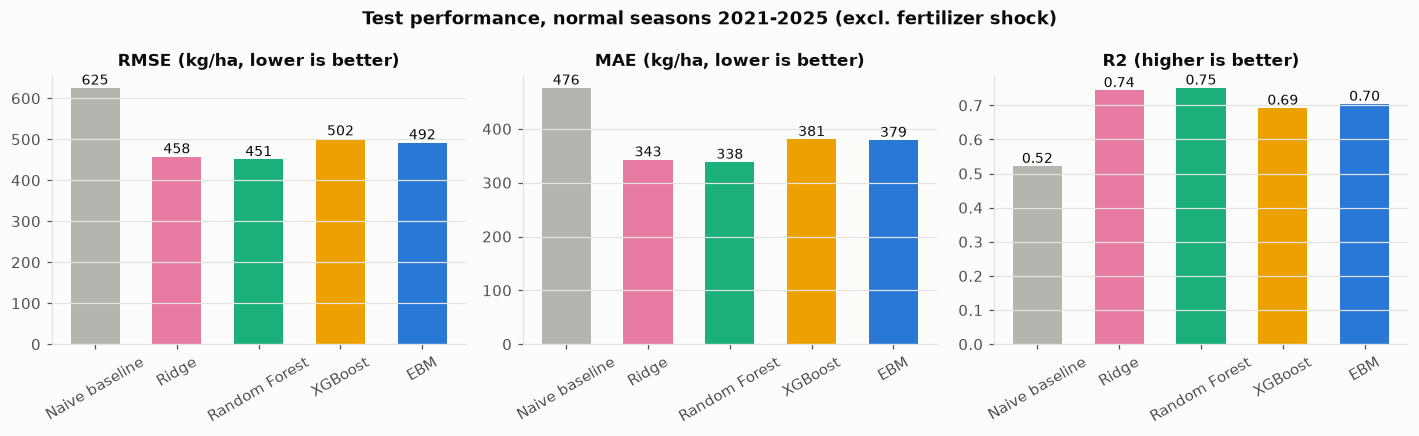

In [12]:
order = ["Naive baseline", "Ridge", "Random Forest", "XGBoost", "EBM"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    d = test_scores[test_scores.subset == "Normal seasons"].set_index("model").loc[order, metric]
    bars = ax.bar(order, d.values, color=[COLORS[m] for m in order], width=0.6)
    for b, v in zip(bars, d.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.2f}" if metric == "R2" else f"{v:,.0f}",
                ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_title(metric + (" (higher is better)" if metric == "R2" else " (kg/ha, lower is better)"), fontsize=11)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="x", visible=False)
fig.suptitle("Test performance, normal seasons 2021-2025 (excl. fertilizer shock)", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "model_01_test_metrics")

## 10. Predicted vs actual (test set, EBM)

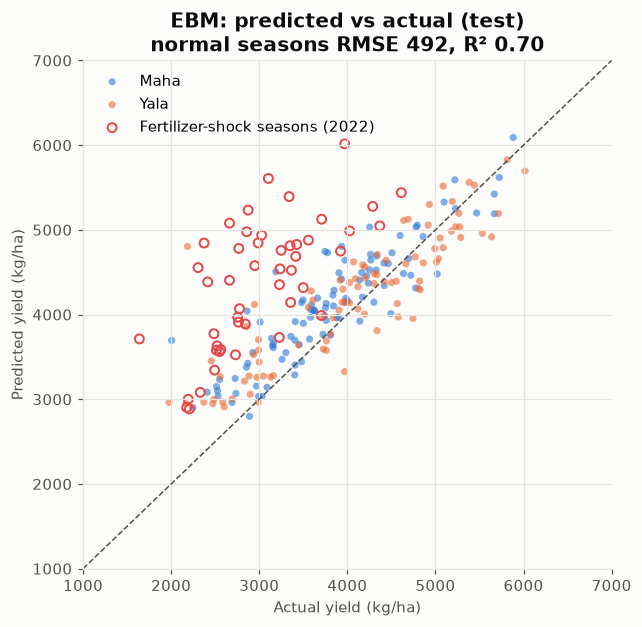

In [13]:
best_name = "EBM"
p = preds[best_name]
fig, ax = plt.subplots(figsize=(6.2, 6))
for s, c in SEASON_COLORS.items():
    m = (test.season.values == s) & normal
    ax.scatter(y_te.values[m], p[m], s=22, alpha=0.6, color=c, edgecolor="none", label=f"{s}")
ax.scatter(y_te.values[~normal], p[~normal], s=34, facecolor="none", edgecolor="#e34948", lw=1.3,
           label="Fertilizer-shock seasons (2022)")
lims = [1000, 7000]
ax.plot(lims, lims, color=INK2, lw=1, ls="--"); ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual yield (kg/ha)"); ax.set_ylabel("Predicted yield (kg/ha)")
r = test_scores.query("model == @best_name and subset == 'Normal seasons'").iloc[0]
ax.set_title(f"EBM: predicted vs actual (test)\nnormal seasons RMSE {r.RMSE:,.0f}, R² {r.R2:.2f}")
ax.legend(frameon=False, loc="upper left")
save(fig, "model_02_ebm_pred_vs_actual")

## 11. National yield, actual vs predicted, per test season

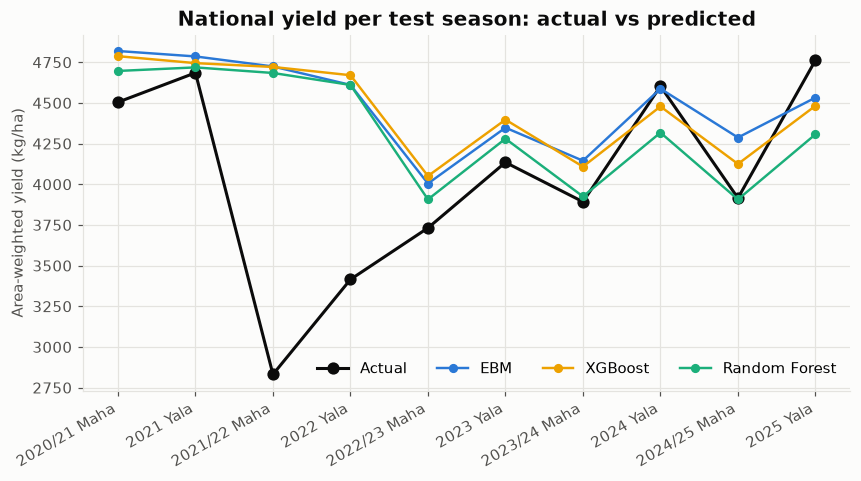

,Actual,EBM,XGBoost,Random Forest
season_label,,,,
2020/21 Maha,4505.0,4819.0,4787.0,4696.0
2021 Yala,4685.0,4786.0,4745.0,4718.0
2021/22 Maha,2831.0,4724.0,4721.0,4684.0
2022 Yala,3415.0,4611.0,4670.0,4610.0
2022/23 Maha,3732.0,4005.0,4051.0,3907.0
2023 Yala,4135.0,4348.0,4397.0,4280.0
2023/24 Maha,3892.0,4145.0,4108.0,3925.0
2024 Yala,4603.0,4587.0,4478.0,4317.0
2024/25 Maha,3915.0,4287.0,4125.0,3907.0


In [14]:
t = test.assign(**{f"pred_{k}": v for k, v in preds.items()})
w = t.harvested_total
nat = t.groupby("season_label").apply(lambda g: pd.Series(
    {"Actual": np.average(g[TARGET], weights=g.harvested_total),
     **{k: np.average(g[f"pred_{k}"], weights=g.harvested_total) for k in ["EBM", "XGBoost", "Random Forest"]}}))
key = {lab: (int(lab[:4]) + (0.5 if "Maha" in lab else 0)) for lab in nat.index}
nat = nat.loc[sorted(nat.index, key=lambda l: key[l])]

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(nat))
ax.plot(x, nat["Actual"], color=INK, marker="o", ms=7, label="Actual")
for k in ["EBM", "XGBoost", "Random Forest"]:
    ax.plot(x, nat[k], color=COLORS[k], marker="o", ms=5, lw=1.6, label=k)
ax.set_xticks(x, nat.index, rotation=30, ha="right")
ax.set_ylabel("Area-weighted yield (kg/ha)")
ax.set_title("National yield per test season: actual vs predicted")
ax.legend(frameon=False, ncol=4, loc="lower right")
save(fig, "model_03_national_test_seasons")
nat.round(0)

## 12. Errors by district (EBM, normal test seasons)

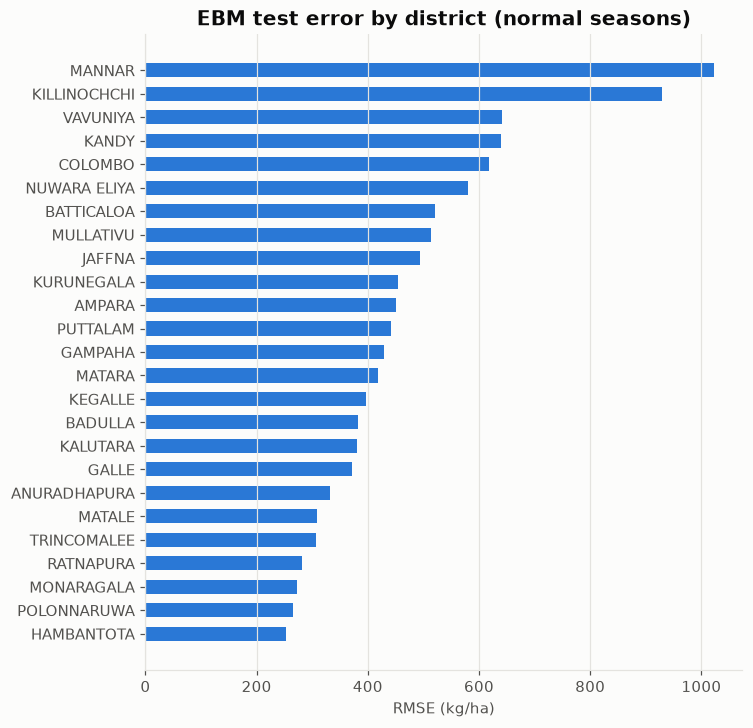

,bias,RMSE
district,,
NUWARA ELIYA,285.0,580.0
COLOMBO,496.0,619.0
KANDY,395.0,639.0
VAVUNIYA,380.0,641.0
KILLINOCHCHI,733.0,930.0
MANNAR,285.0,1022.0


In [15]:
err = test[normal].assign(error=(preds["EBM"] - y_te.values)[normal])
by_d = err.groupby("district").error.agg(["mean", lambda e: np.sqrt(np.mean(e**2))]).rename(columns={"mean": "bias", "<lambda_0>": "RMSE"})
by_d = by_d.sort_values("RMSE")
fig, ax = plt.subplots(figsize=(7, 7.5))
ax.barh(by_d.index, by_d.RMSE, color="#2a78d6", height=0.6)
ax.set_xlabel("RMSE (kg/ha)"); ax.set_title("EBM test error by district (normal seasons)")
ax.grid(axis="y", visible=False)
save(fig, "model_04_ebm_error_by_district")
by_d.round(0).tail(6)

## 13. Error by climate zone and by test year

The districts are grouped into Sri Lanka's three agro-climatic zones. This checks whether the model is equally reliable everywhere,
which matters for **fairness**: a model that is accurate only in the main rice districts would serve the others poorly.

model,Naive baseline,Ridge,Random Forest,XGBoost,EBM,rows
zone,,,,,,
Dry,982.0,864.0,898.0,926.0,904.0,120
Intermediate,931.0,782.0,825.0,835.0,828.0,30
Wet,570.0,551.0,511.0,581.0,590.0,90


model,Naive baseline,Ridge,Random Forest,XGBoost,EBM
season_label,,,,,
2020/21 Maha,579.0,406.0,457.0,479.0,450.0
2021 Yala,429.0,454.0,446.0,461.0,477.0
2021/22 Maha,1575.0,1643.0,1683.0,1704.0,1717.0
2022 Yala,1214.0,1095.0,1158.0,1202.0,1136.0
2022/23 Maha,820.0,404.0,373.0,459.0,433.0
2023 Yala,727.0,418.0,314.0,439.0,389.0
2023/24 Maha,518.0,442.0,393.0,461.0,507.0
2024 Yala,714.0,664.0,661.0,746.0,718.0
2024/25 Maha,367.0,425.0,370.0,470.0,511.0


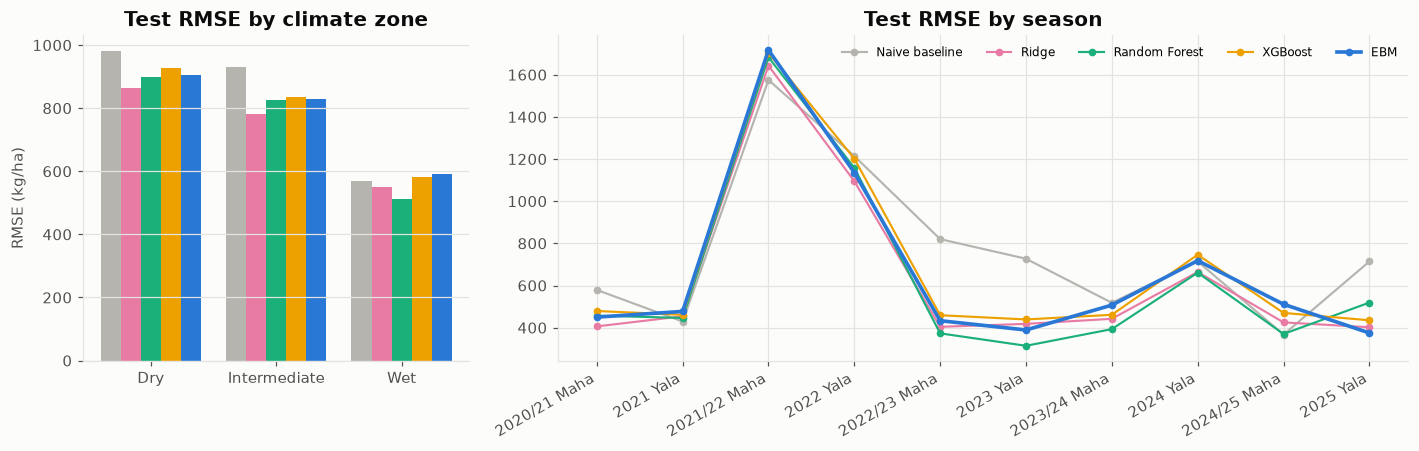

In [16]:
ZONES = {
    "Dry": ["ANURADHAPURA", "POLONNARUWA", "HAMBANTOTA", "AMPARA", "TRINCOMALEE", "BATTICALOA", "JAFFNA",
            "MANNAR", "VAVUNIYA", "MULLATIVU", "KILLINOCHCHI", "PUTTALAM", "MONARAGALA", "MAHAWELI H", "UDAWALAWE"],
    "Intermediate": ["KURUNEGALA", "MATALE", "BADULLA"],
    "Wet": ["COLOMBO", "GAMPAHA", "KALUTARA", "GALLE", "MATARA", "RATNAPURA", "KEGALLE", "KANDY", "NUWARA ELIYA"],
}
zone_of = {d: z for z, ds in ZONES.items() for d in ds}
t["zone"] = t.district.map(zone_of)

def group_errors(by):
    rows = []
    for key, g in t.groupby(by):
        for name in order:
            e = g[f"pred_{name}"] - g[TARGET]
            rows.append({by: key, "model": name, "RMSE": np.sqrt(np.mean(e**2)), "n": len(g)})
    return pd.DataFrame(rows).pivot(index=by, columns="model", values="RMSE")[order].round(0)

zone_err, year_err = group_errors("zone"), group_errors("season_label")
year_err = year_err.loc[sorted(year_err.index, key=lambda l: int(l[:4]) + (0.5 if "Maha" in l else 0))]
display(zone_err.assign(rows=t.groupby("zone").size()))
display(year_err)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
w = 0.16
for i, name in enumerate(order):
    axes[0].bar(np.arange(len(zone_err)) + (i - 2) * w, zone_err[name], width=w, color=COLORS[name], label=name)
    axes[1].plot(range(len(year_err)), year_err[name], marker="o", ms=4, color=COLORS[name], label=name,
                 lw=2.4 if name == "EBM" else 1.4)
axes[0].set_xticks(range(len(zone_err)), zone_err.index); axes[0].set_ylabel("RMSE (kg/ha)")
axes[0].set_title("Test RMSE by climate zone"); axes[0].grid(axis="x", visible=False)
axes[1].set_xticks(range(len(year_err)), year_err.index, rotation=30, ha="right")
axes[1].set_title("Test RMSE by season"); axes[1].legend(frameon=False, ncol=5, fontsize=8, loc="upper right")
fig.tight_layout()
save(fig, "model_05_error_by_zone_and_season")

## 14. Effect of the lag features

This compares the first run (weather and irrigation only) with the final run (plus lag features), using the same split and
the same tuning procedure.

,Without lags,With lags,Change %
model,,,
Naive baseline,773.1,844.1,9.2
Ridge,870.3,750.7,-13.7
Random Forest,833.0,765.7,-8.1
XGBoost,902.7,801.2,-11.2
EBM,922.4,790.3,-14.3


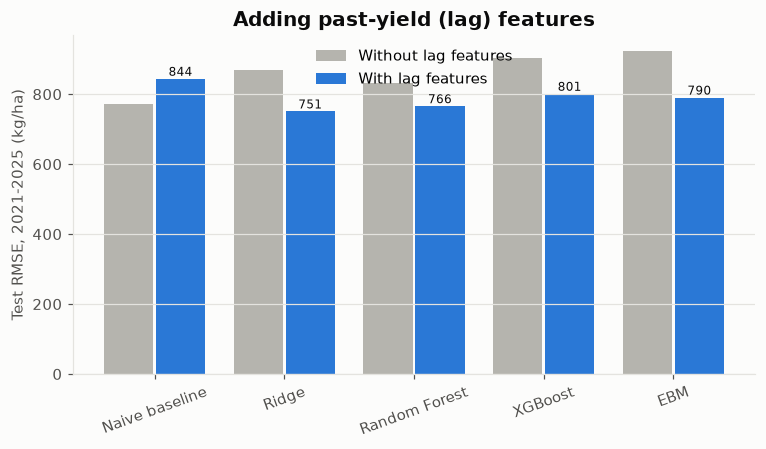

Note: the naive baseline also changed (5-season mean -> last same-season yield).


In [17]:
no_lag = pd.read_csv(ROOT / "reports" / "test_scores_no_lag.csv")
cmp = pd.DataFrame({
    "Without lags": no_lag.query("subset == 'All test (2021-25)'").set_index("model").RMSE,
    "With lags": test_scores.query("subset == 'All test (2021-25)'").set_index("model").RMSE,
}).loc[order]
cmp["Change %"] = (cmp["With lags"] / cmp["Without lags"] - 1) * 100
display(cmp.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(order))
ax.bar(x - 0.2, cmp["Without lags"], width=0.38, color="#b5b4ae", label="Without lag features")
ax.bar(x + 0.2, cmp["With lags"], width=0.38, color="#2a78d6", label="With lag features")
for i, v in enumerate(cmp["With lags"]):
    ax.text(i + 0.2, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=8, color=INK)
ax.set_xticks(x, order, rotation=20); ax.set_ylabel("Test RMSE, 2021-2025 (kg/ha)")
ax.set_title("Adding past-yield (lag) features"); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
save(fig, "model_06_lag_feature_effect")
print("Note: the naive baseline also changed (5-season mean -> last same-season yield).")

## 15. Save models and outputs for notebook 03 and the app

In [18]:
for name, model in final.items():
    joblib.dump(model, MODELS / f"{name.lower().replace(' ', '_')}.joblib")
meta = {"features": FEATURES, "categorical": CATEGORICAL, "numeric": NUMERIC, "target": TARGET,
        "train_years": [int(trval.year.min()), int(trval.year.max())], "test_years": [2021, 2025],
        "best_params": {"Ridge": ridge_best, "Random Forest": rf_best, "XGBoost": xgb_best, "EBM": ebm_best},
        "districts": sorted(df.district.unique().tolist())}
(MODELS / "model_meta.json").write_text(json.dumps(meta, indent=2, default=str))
test_scores.round(4).to_csv(ROOT / "reports" / "test_scores.csv", index=False)
val_scores.round(4).to_csv(ROOT / "reports" / "validation_scores.csv")
t.drop(columns=[c for c in t.columns if c.startswith("pred_") and c != "pred_EBM"]).to_csv(
    ROOT / "data_processed" / "test_predictions.csv", index=False)
print(sorted(p.name for p in MODELS.iterdir()))

['.gitkeep', 'ebm.joblib', 'model_meta.json', 'random_forest.joblib', 'ridge.joblib', 'xgboost.joblib']


## 16. Results and discussion

### Test performance (2021–2025, never seen during training or tuning)

| Model | RMSE, normal seasons | MAE, normal seasons | R², normal seasons | RMSE, all test seasons | RMSE, 2022 shock seasons |
|---|---|---|---|---|---|
| Naive baseline (last same-season yield) | 625 | 476 | 0.52 | 844 | 1,414 |
| Ridge | 458 | 343 | 0.74 | 751 | 1,407 |
| Random Forest | **451** | **338** | **0.75** | 766 | 1,455 |
| XGBoost | 502 | 381 | 0.69 | 801 | 1,484 |
| **EBM** (new algorithm) | 492 | 379 | 0.70 | 790 | 1,468 |

All values are in kg/ha. "Normal seasons" excludes 2021/22 Maha and 2022 Yala.

### What the results mean
1. **Every model clearly beats the naive baseline in normal seasons.** RMSE is 20–28% lower, or 450–500 kg/ha instead of 625.
   An error of about 490 kg/ha is about **11–12% of a typical yield** (MAPE 11.2% for EBM).
2. **EBM is within about 9% of the most accurate model** (Random Forest, RMSE 451) and is better than XGBoost.
   Unlike RF and XGBoost, EBM is a **glass box**. The best EBM has **0 interactions**, so every prediction is exactly a sum of
   21 one-feature contributions that can be plotted and checked (notebook 03).
   The trade-off between accuracy and interpretability here is small.
3. **Ridge is surprisingly strong.** Once past yields are included, much of the signal is close to linear: "this season is like
   recent seasons, adjusted for weather and irrigation". This is a useful finding in itself.
4. **No model predicted the fertilizer shock.** RMSE in 2021/22 Maha and 2022 Yala is about 1,400–1,500 kg/ha for every model.
   The 2021 chemical fertilizer ban had no precedent in the training data and no weather signal, so this is expected.
   It is an important limitation: these models **cannot anticipate policy shocks**.
5. **The lag features allowed recovery after the shock.** From 2022/23 onward, the models' errors fall back to about
   300–500 kg/ha, except 2024 Yala at about 700. The naive baseline's errors stay higher in most seasons, at about 520–820. Adding past-yield features reduced
   EBM's test RMSE by **14%** (922 → 790). Without them, every model lost to the baseline (see `test_scores_no_lag.csv`).
6. **Errors differ by zone.** RMSE is about 900 kg/ha in the dry zone, against about 550–590 in the wet zone.
   - Most of this comes from the shock seasons. The dry zone is the main rice bowl and had the largest fertilizer-ban losses.
   - Some dry/northern districts also have larger errors, notably Mannar and Kilinochchi. They have shorter records because
     of war-year gaps, and more variable rainfed cultivation.
   - **Fairness implication:** predictions for the northern districts are less reliable and should be used with more caution.

### Hyperparameter choices (best on the 2018–2020 validation years)
- **EBM:** `interactions=0`, `max_leaves=3`, `min_samples_leaf=2`, `learning_rate=0.03`, `max_bins=256`.
  Adding 5 interactions made validation slightly worse, so the simpler additive model was kept.
- **Random Forest:** 500 trees, `max_features=0.5`, `min_samples_leaf=4`, no depth limit.
- **XGBoost:** 300 trees, `learning_rate=0.03`, `max_depth=5`, `subsample=0.8`, `colsample_bytree=0.7`, `reg_lambda=5`.
- **Ridge:** `alpha=30`.

### Model chosen for explainability and the app
We choose **EBM**. It is the new algorithm, its accuracy is competitive (R² 0.70 on unseen normal seasons), and it is fully interpretable.
Random Forest is kept as the accuracy benchmark, and SHAP/LIME in notebook 03 are applied to both models.
